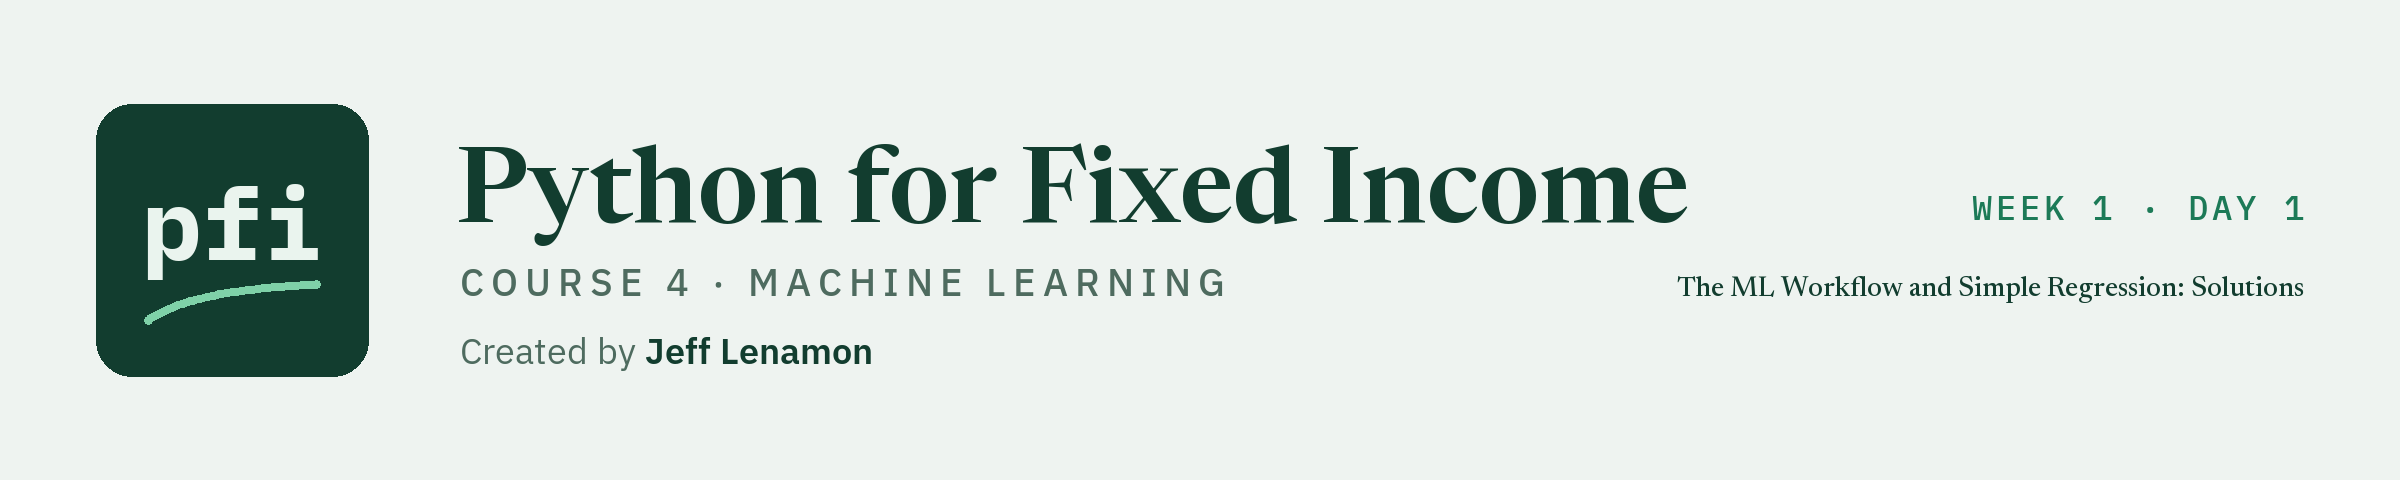

# The ML Workflow and Simple Regression: Solutions

Week 1, Day 1. The full notebook with every exercise worked. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course04_machine_learning/week1/day1/01_the_ml_workflow_and_simple_regression_solutions.ipynb)

# Problem Statement

## Business Context

A credit team has taken on a benchmark of 821 corporate bonds from 150 issuers, rated AAA to CCC.
It wants to know how much of the difference in spread between bonds one characteristic can account for: the rating, the duration, or the coupon.
The answer has to hold on bonds the model has never seen, because those are the only bonds a model is ever asked about.
The bonds and issuers are invented for this course.

## Objectives

Explore the file, fit a simple linear regression of OAS on each candidate, score each model in bp on bonds it was not fitted on, and find the single characteristic that says the most about spread.

## Data Dictionary

`benchmark.csv`, one row per bond:

1. `cusip`: the bond's identifier
2. `issuer`: the issuer's name, with `ticker` its short code
3. `rating`: credit rating, AAA to CCC
4. `coupon`: annual coupon, % of par
5. `price`: clean price, per 100 of par
6. `yield_pct`: yield to maturity, % (a Treasury yield plus the OAS)
7. `oas`: option-adjusted spread, bp, **the target**
8. `duration`: modified duration, years
9. `dts`: spread duration times OAS
10. `amount_outstanding`: face value outstanding, dollars

The file's other columns (dates, sector, accrued interest, spread duration, market value, weight) are not used today.

`ratings.csv` adds `score` (1 for AAA up to 18 for CCC, one step per notch) and `grade` (Investment Grade or High Yield).

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data
import numpy as np
import pandas as pd

# to draw charts
import matplotlib.pyplot as plt
import seaborn as sns

# to split the bonds into training and test sets
from sklearn.model_selection import train_test_split

# to build a linear regression model
from sklearn.linear_model import LinearRegression

# to measure how far a model's spreads are from the actual spreads
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# one look for every chart, and plain numbers with three decimals in every table
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.float_format", "{:,.3f}".format)

# Loading the Data

## Reading the Bonds and the Rating Scale

In [3]:
# the 821 bonds, and the table that turns each rating into a score
bonds = pd.read_csv(DATA + "benchmark.csv")
ratings = pd.read_csv(DATA + "ratings.csv")

## Adding the Rating Score to Each Bond

In [4]:
# give every bond its rating score and its grade, matched on the rating
data = bonds.merge(ratings[["rating", "score", "grade"]], on="rating")

# Data Overview

## Checking the First Five Rows

Q. What does one row look like?

In [5]:
data.head()

,as_of_date,cusip,ticker,issuer,sector,rating,coupon,maturity,price,price_date,...,yield_pct,oas,duration,spread_duration,dts,amount_outstanding,market_value,weight_pct,score,grade
0,2026-09-30,99001BAA4,QVNE,Quorvane Energy,Energy,BBB,4.875,2034-01-14,98.882,2026-09-30,...,5.059,83,6.000,6.000,498.000,2400000000,"2,397,864,000.000",0.208,9,Investment Grade
1,2026-09-30,99001BAB2,QVNE,Quorvane Energy,Energy,BBB,5.750,2035-08-08,101.558,2026-09-30,...,5.524,122,6.834,6.834,833.700,1750000000,"1,791,807,500.000",0.155,9,Investment Grade
2,2026-09-30,99001BAC0,QVNE,Quorvane Energy,Energy,BBB,5.000,2041-01-22,93.261,2026-09-30,...,5.694,123,9.848,9.848,"1,211.300",300000000,"282,615,000.000",0.025,9,Investment Grade
3,2026-09-30,99001BAD8,QVNE,Quorvane Energy,Energy,BBB,3.875,2027-09-17,99.355,2026-09-30,...,4.565,88,0.933,0.933,82.100,2350000000,"2,338,132,500.000",0.202,9,Investment Grade
4,2026-09-30,99001BAE6,QVNE,Quorvane Energy,Energy,BBB,5.375,2034-10-02,98.976,2026-09-30,...,5.535,127,6.256,6.256,794.500,1550000000,"1,575,327,000.000",0.136,9,Investment Grade


One row per bond; an issuer appears once for each of its bonds.

## Checking the Shape of the Data

Q. How many bonds and columns?

In [6]:
data.shape

(821, 21)

821 bonds and 21 columns.

## Checking the Column Types

Q. Which columns are numbers and which are text?

In [7]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 821 entries, 0 to 820
Data columns (total 21 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   as_of_date          821 non-null    str    
 1   cusip               821 non-null    str    
 2   ticker              821 non-null    str    
 3   issuer              821 non-null    str    
 4   sector              821 non-null    str    
 5   rating              821 non-null    str    
 6   coupon              821 non-null    float64
 7   maturity            821 non-null    str    
 8   price               821 non-null    float64
 9   price_date          821 non-null    str    
 10  accrued             821 non-null    float64
 11  yield_pct           821 non-null    float64
 12  oas                 821 non-null    int64  
 13  duration            821 non-null    float64
 14  spread_duration     821 non-null    float64
 15  dts                 821 non-null    float64
 16  amount_outstanding 

12 numeric and 9 text columns; the three candidates, `score`, `duration`, and `coupon`, are numeric.

## Checking the Statistical Summary

Q. What does a typical spread look like?

In [8]:
data.describe()

,coupon,price,accrued,yield_pct,oas,duration,spread_duration,dts,amount_outstanding,market_value,weight_pct,score
count,821.000,821.000,821.000,821.000,821.000,821.000,821.000,821.000,821.000,821.000,821.000,821.000
mean,5.852,99.466,1.502,5.985,179.079,5.981,5.981,"1,034.756","1,391,778,319.123","1,406,957,718.027",0.122,9.248
std,1.655,7.105,0.998,1.891,185.523,3.253,3.253,"1,042.801","658,029,211.723","678,745,843.856",0.059,3.433
min,1.500,40.306,0.023,3.925,15.000,0.915,0.915,24.000,"300,000,000.000","260,181,000.000",0.022,1.000
25%,4.750,96.384,0.683,4.971,79.000,3.434,3.434,362.100,"850,000,000.000","824,730,000.000",0.071,7.000
50%,5.625,99.637,1.373,5.493,125.000,5.919,5.919,695.300,"1,350,000,000.000","1,373,679,000.000",0.119,9.000
75%,6.750,102.822,2.121,6.328,210.000,7.743,7.743,"1,318.200","1,950,000,000.000","1,954,321,000.000",0.169,11.000
max,11.000,127.511,5.159,25.140,"2,074.000",16.042,16.042,"8,410.100","2,500,000,000.000","2,940,575,000.000",0.255,18.000


The same summary is easier to read turned on its side.
`.T` (transpose) swaps rows and columns: one row per column of the file, one column per statistic.

In [9]:
# the same summary, transposed: one row per column of the file
data.describe().T

,count,mean,std,min,25%,50%,75%,max
coupon,821.000,5.852,1.655,1.500,4.750,5.625,6.750,11.000
price,821.000,99.466,7.105,40.306,96.384,99.637,102.822,127.511
accrued,821.000,1.502,0.998,0.023,0.683,1.373,2.121,5.159
yield_pct,821.000,5.985,1.891,3.925,4.971,5.493,6.328,25.140
oas,821.000,179.079,185.523,15.000,79.000,125.000,210.000,"2,074.000"
duration,821.000,5.981,3.253,0.915,3.434,5.919,7.743,16.042
spread_duration,821.000,5.981,3.253,0.915,3.434,5.919,7.743,16.042
dts,821.000,"1,034.756","1,042.801",24.000,362.100,695.300,"1,318.200","8,410.100"
amount_outstanding,821.000,"1,391,778,319.123","658,029,211.723","300,000,000.000","850,000,000.000","1,350,000,000.000","1,950,000,000.000","2,500,000,000.000"
market_value,821.000,"1,406,957,718.027","678,745,843.856","260,181,000.000","824,730,000.000","1,373,679,000.000","1,954,321,000.000","2,940,575,000.000"


The median OAS is 125 bp but the mean is 179 bp: a few very wide bonds pull the mean up.

The widest bond is at 2,074 bp; three quarters sit below 210 bp.

## Checking for Missing Values

Q. Is any value missing?

In [10]:
data.isnull().sum()

as_of_date            0
cusip                 0
ticker                0
issuer                0
sector                0
rating                0
coupon                0
maturity              0
price                 0
price_date            0
accrued               0
yield_pct             0
oas                   0
duration              0
spread_duration       0
dts                   0
amount_outstanding    0
market_value          0
weight_pct            0
score                 0
grade                 0
dtype: int64

Every column is complete.

## Checking for Duplicate Values

Q. Is any bond in the file twice?

In [11]:
# how many bonds have a CUSIP that appears more than once
print(data["cusip"].duplicated().sum())

0


Each bond is in the file once.

**The file is complete and clean, so we can go straight to exploring it.**

# Exploratory Data Analysis

The mean spread sits well above the median.
The charts show why.

## Univariate Analysis

### OAS

Q. Where do most spreads sit, and how far does the tail run?

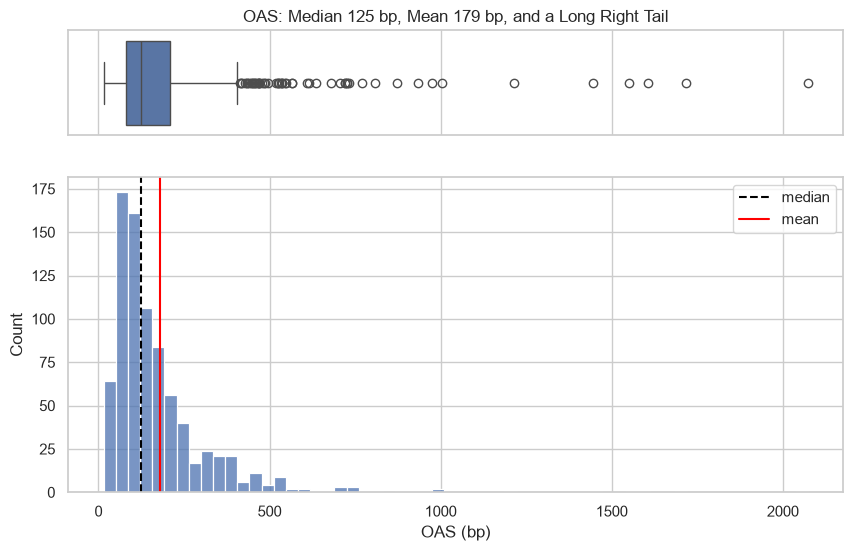

In [12]:
# the spread of every bond: a box plot on top, a histogram below
fig, (top, bottom) = plt.subplots(2, 1, sharex=True, figsize=(10, 6), height_ratios=[1, 3])
sns.boxplot(data=data, x="oas", ax=top)
sns.histplot(data=data, x="oas", ax=bottom)

# the median and the mean, so the gap between them shows
bottom.axvline(data["oas"].median(), color="black", linestyle="--", label="median")
bottom.axvline(data["oas"].mean(), color="red", label="mean")
bottom.legend()
bottom.set_xlabel("OAS (bp)")
top.set_title("OAS: Median 125 bp, Mean 179 bp, and a Long Right Tail")
plt.show()

The middle half of the bonds sit between 79 and 210 bp, with a long tail to the right: 7 bonds are above 1,000 bp.

Those few wide bonds pull the mean to the right of the median.

**A few very wide bonds will weigh heavily on any line we fit, so we keep an eye on them from here on.**

### Bonds by Rating

Q. How many bonds sit at each rating?

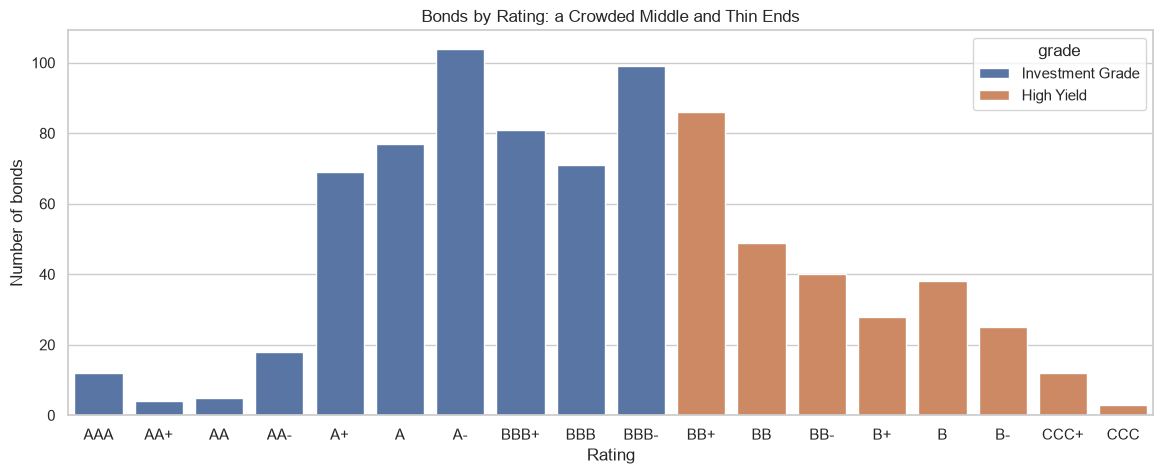

In [13]:
# how many bonds carry each rating, from AAA down to CCC, coloured by grade
rating_order = ratings["rating"]
plt.figure(figsize=(14, 5))
sns.countplot(data=data, x="rating", order=rating_order, hue="grade")
plt.xlabel("Rating")
plt.ylabel("Number of bonds")
plt.title("Bonds by Rating: a Crowded Middle and Thin Ends")
plt.show()

The middle of the scale is crowded; the ends are thin: CCC has 3 bonds, AA+ 4, AA 5.

**Any spread a model gives at the very top or bottom of the scale rests on only a handful of bonds.**

## Bivariate Analysis

**Predict 1**

Before the next chart, write down a number between -1 and 1: the correlation between a bond's OAS and its duration in this file.

### OAS Against Each Candidate

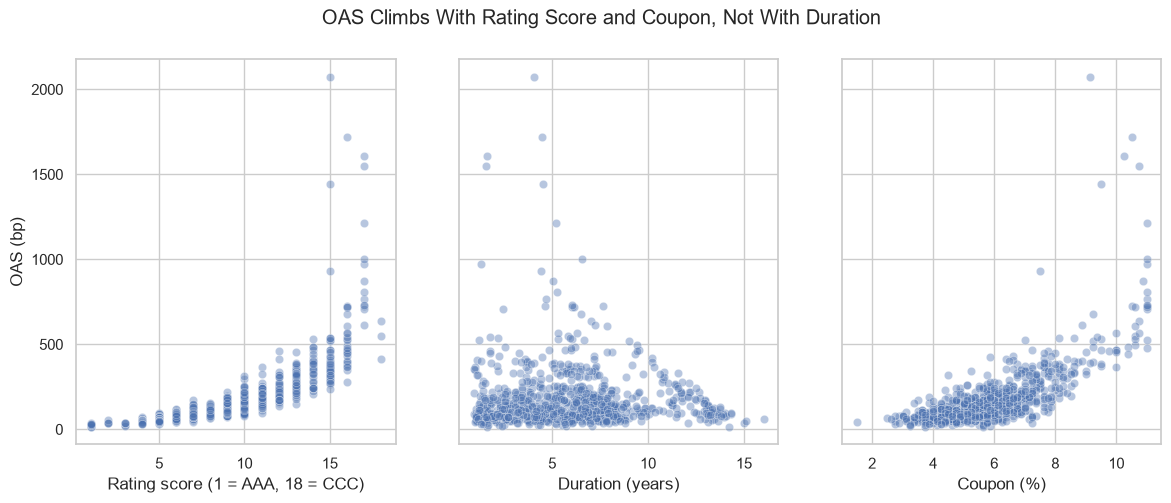

In [14]:
# OAS against rating score, duration, and coupon, on the same OAS axis
fig, axes = plt.subplots(1, 3, figsize=(14, 5), sharey=True)
sns.scatterplot(data=data, x="score", y="oas", alpha=0.4, ax=axes[0])
sns.scatterplot(data=data, x="duration", y="oas", alpha=0.4, ax=axes[1])
sns.scatterplot(data=data, x="coupon", y="oas", alpha=0.4, ax=axes[2])
axes[0].set_xlabel("Rating score (1 = AAA, 18 = CCC)")
axes[1].set_xlabel("Duration (years)")
axes[2].set_xlabel("Coupon (%)")
axes[0].set_ylabel("OAS (bp)")
fig.suptitle("OAS Climbs With Rating Score and Coupon, Not With Duration")
plt.show()

OAS climbs with rating score, slowly through investment grade and steeply through high yield.

OAS climbs with coupon too; against duration the cloud is flat.

### Correlation Heatmap

Q. How strongly does each column move with OAS?

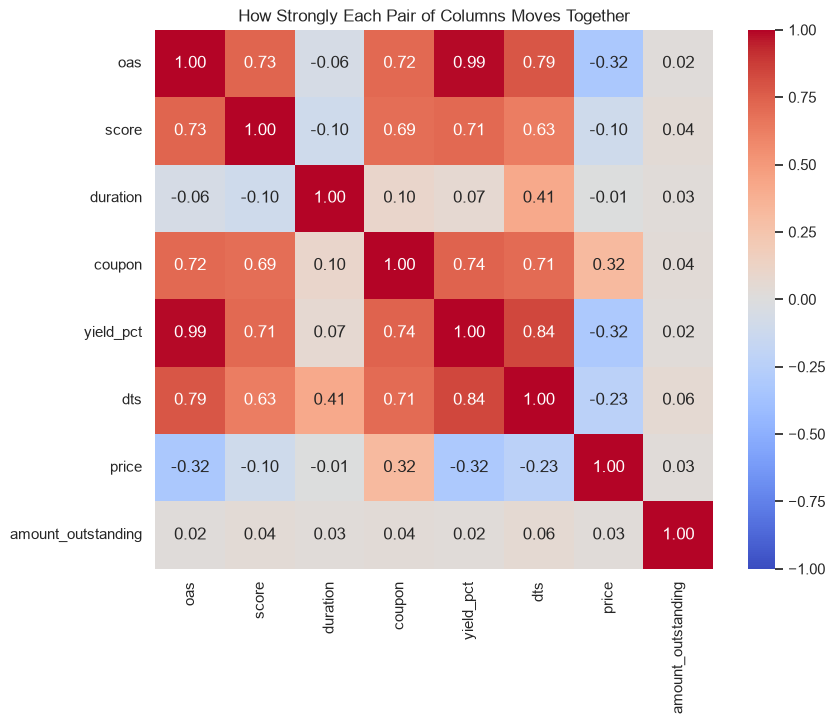

In [15]:
# how strongly each pair of columns moves together, from -1 to 1
columns = ["oas", "score", "duration", "coupon", "yield_pct", "dts", "price", "amount_outstanding"]
plt.figure(figsize=(9, 7))
sns.heatmap(data[columns].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("How Strongly Each Pair of Columns Moves Together")
plt.show()

OAS correlates 0.73 with the rating score and 0.72 with the coupon.

With duration the correlation is -0.06, close to zero.

Check your Predict 1.

`yield_pct` (0.99) and `dts` (0.79) are built from OAS itself, so they would hand a model the answer.

**We take rating score, duration, and coupon as the three candidates, and leave out yield and DTS because they contain the spread.**

### OAS by Rating

Q. How does the spread step from one rating to the next?

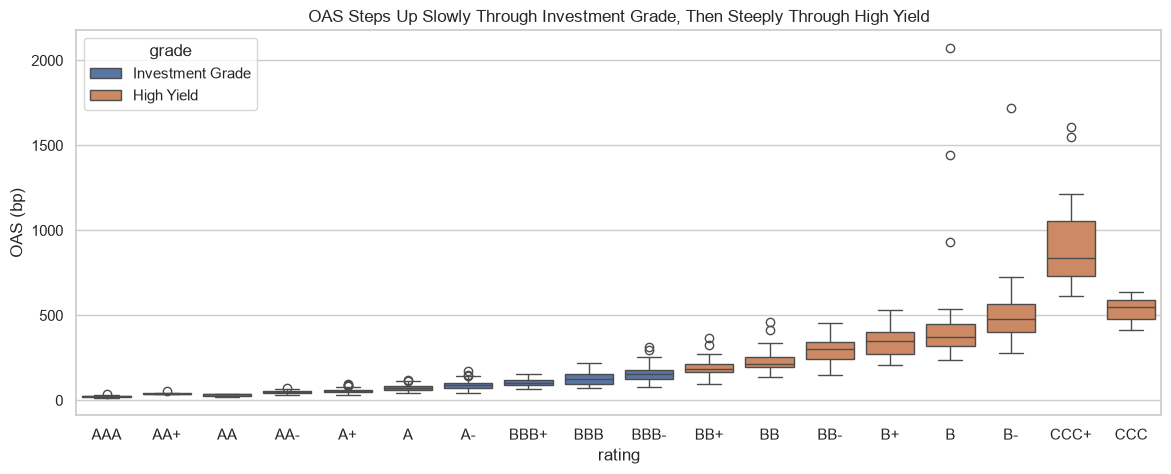

In [16]:
# one box of spreads per rating, AAA on the left, coloured by grade
plt.figure(figsize=(14, 5))
sns.boxplot(data=data, x="rating", y="oas", order=rating_order, hue="grade")
plt.ylabel("OAS (bp)")
plt.title("OAS Steps Up Slowly Through Investment Grade, Then Steeply Through High Yield")
plt.show()

The median spread climbs from about 24 bp at AAA to several hundred bp at the bottom of the scale.

The steps are small at the top and large at the bottom, so the relationship curves upward.

CCC sits below CCC+, but CCC has only 3 bonds, too few to read anything into.

**A straight line will struggle at both ends of this curve. We fit one anyway, because it is the simplest model there is, and measure how far it misses.**

# Data Preparation for Modeling

## Choosing the Features and the Target

In [17]:
# the three candidate features, and the target: OAS in bp
X = data[["score", "duration", "coupon"]]
y = data["oas"]

## Splitting Into Training and Test Bonds

In [18]:
# hold back a quarter of the bonds; the seed makes the same split on every run
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=SEED)
print("Training bonds:", len(X_train), " Test bonds:", len(X_test))

Training bonds: 615  Test bonds: 206


615 training bonds to fit the models on, and 206 test bonds the models never see.

**The test bonds stay untouched until the models are scored: that score is the only honest one.**

# Model Building

## Your Turn: Fit the Line by Eye

Move the two sliders until the red line runs through the bonds.

Each gray line is one miss.

MAE is their average length.

RMSE counts the long ones far more.

Aim for the lowest RMSE you can find, and write down your slope and intercept.

In [19]:
# your turn: move the two sliders until the red line runs through the bonds
from ipywidgets import interact

def draw_line(slope=0.0, intercept=180.0):
    fitted = intercept + slope * X_train["score"]
    plt.scatter(X_train["score"], y_train, alpha=0.3)
    plt.vlines(X_train["score"], y_train, fitted, color="gray", alpha=0.4)  # each gray line is one miss
    plt.plot(X_train["score"], fitted, color="red")
    plt.ylim(-300, 2200)
    plt.xlabel("Rating score (1 = AAA, 18 = CCC)")
    plt.xticks(range(1, 19))
    plt.ylabel("OAS (bp)")
    plt.title("Your Line Through the Training Bonds: Each Gray Line Is One Miss")
    plt.show()
    print("MAE: ", round(mean_absolute_error(y_train, fitted), 1), "bp")
    print("RMSE:", round(np.sqrt(mean_squared_error(y_train, fitted)), 1), "bp")

interact(draw_line, slope=(0.0, 80.0, 1.0), intercept=(-300.0, 300.0, 5.0));

interactive(children=(FloatSlider(value=0.0, description='slope', max=80.0, step=1.0), FloatSlider(value=180.0…

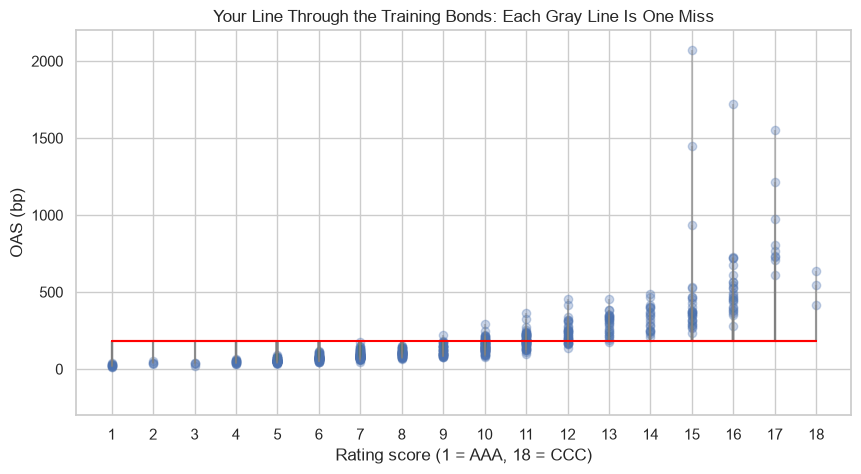

MAE:  115.1 bp
RMSE: 192.6 bp


In [20]:
# the sliders' starting position, drawn as a still picture (sliders do not run on GitHub)
draw_line(slope=0.0, intercept=180.0)

The sliders start at a flat line at 180 bp, about the average spread: MAE 115.1 bp, RMSE 192.6 bp.

R-squared, coming up, scores a line against a flat line at the average like this one.

## Simple Linear Regression - OAS vs Rating Score

Now the computer turns the same two knobs.

In [21]:
# the feature for this model
features_score = ["score"]

# create an empty linear regression model, then fit it to the training bonds
model_score = LinearRegression()
model_score.fit(X_train[features_score], y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[39.05]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['score']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-179.1
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [22]:
# the fitted line, written as an equation
print("OAS = (", round(model_score.coef_[0], 2), ") * score + (", round(model_score.intercept_, 2), ")")

OAS = ( 39.05 ) * score + ( -179.06 )


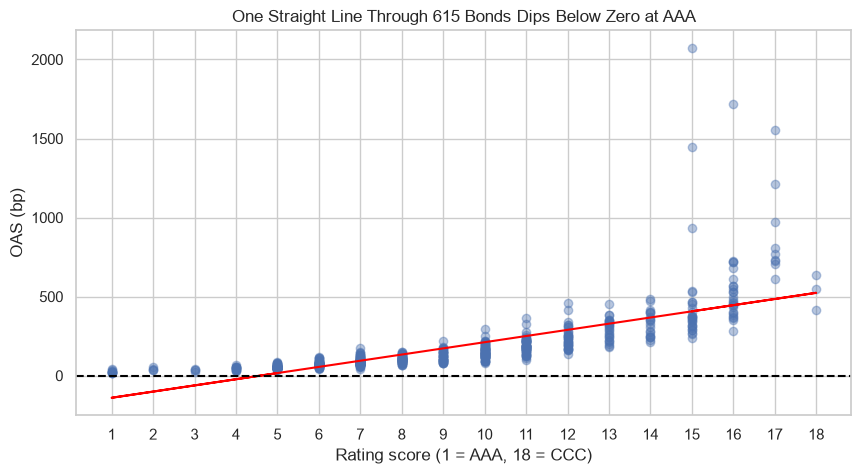

In [23]:
# the training bonds, with the fitted line across them
plt.scatter(X_train["score"], y_train, alpha=0.4)
plt.plot(X_train["score"], model_score.predict(X_train[features_score]), color="red")
plt.axhline(0, color="black", linestyle="--")  # zero spread
plt.xlabel("Rating score (1 = AAA, 18 = CCC)")
plt.xticks(range(1, 19))
plt.ylabel("OAS (bp)")
plt.title("One Straight Line Through 615 Bonds Dips Below Zero at AAA")
plt.show()

This is the least squares line: no other slope and intercept give a smaller sum of squared misses on these bonds, so no slider setting beats its training RMSE of 133.0 bp.

On MAE you can beat it: slope 27 and intercept -90 give a training MAE of 55.8 bp against the line's 65.6.

Least squares shrinks the squared misses, so the few very wide bonds pull the line toward them.

### Interpretation of the Coefficients

The slope is 39.05: each notch down the scale goes with about 39 bp more fitted spread.

The intercept, -179.06 bp, is the line's value at score 0, a rating that does not exist; it only positions the line.

The line gives -140.0 bp at AAA and 523.9 bp at CCC.

A negative spread at AAA shows the wrong shape: the line takes the same step at every notch, and the boxes in the OAS by Rating chart do not.

### Interpretation of R-squared

In [24]:
# R-squared on the training bonds
model_score.score(X_train[features_score], y_train)

0.5227499437906944

Rating score accounts for about 52 percent of the variation in spread among the training bonds.

**Rating gives a workable line. Next we ask whether duration does as well.**

## Simple Linear Regression - OAS vs Duration

In [25]:
# the feature for this model
features_duration = ["duration"]

# create an empty linear regression model, then fit it to the training bonds
model_duration = LinearRegression()
model_duration.fit(X_train[features_duration], y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[-4.13]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['duration']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,205.1
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [26]:
# the fitted line, written as an equation, and its R-squared on the training bonds
print("OAS = (", round(model_duration.coef_[0], 2), ") * duration + (", round(model_duration.intercept_, 2), ")")
print("Training R-squared:", round(model_duration.score(X_train[features_duration], y_train), 3))

OAS = ( -4.13 ) * duration + ( 205.11 )
Training R-squared: 0.005


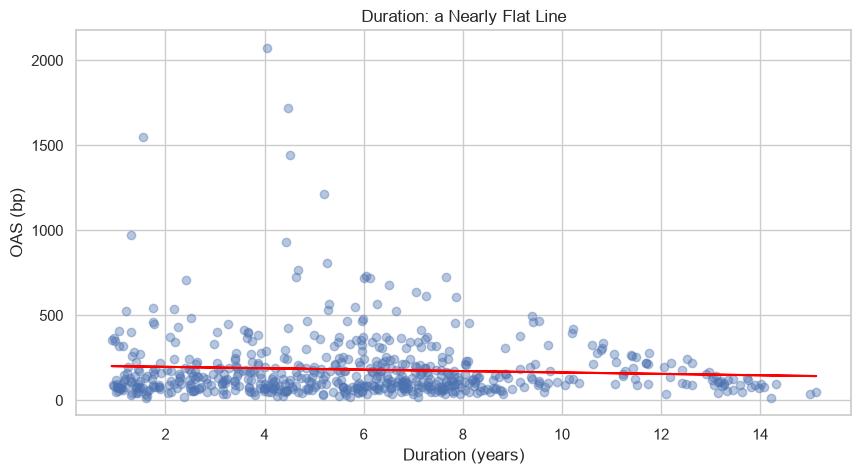

In [27]:
# the training bonds, with the fitted line across them
plt.scatter(X_train["duration"], y_train, alpha=0.4)
plt.plot(X_train["duration"], model_duration.predict(X_train[features_duration]), color="red")
plt.xlabel("Duration (years)")
plt.ylabel("OAS (bp)")
plt.title("Duration: a Nearly Flat Line")
plt.show()

### Interpretation

Each extra year of duration goes with about 4 bp less fitted spread: the line is nearly flat and cannot tell a BBB from a B.

Duration accounts for about 0.5 percent of the variation in spread.

**On its own, duration says next to nothing about spread. We try the coupon.**

## Simple Linear Regression - OAS vs Coupon

In [28]:
# the feature for this model
features_coupon = ["coupon"]

# create an empty linear regression model, then fit it to the training bonds
model_coupon = LinearRegression()
model_coupon.fit(X_train[features_coupon], y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[80.62]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['coupon']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-292.8
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [29]:
# the fitted line, written as an equation, and its R-squared on the training bonds
print("OAS = (", round(model_coupon.coef_[0], 2), ") * coupon + (", round(model_coupon.intercept_, 2), ")")
print("Training R-squared:", round(model_coupon.score(X_train[features_coupon], y_train), 3))

OAS = ( 80.62 ) * coupon + ( -292.77 )
Training R-squared: 0.504


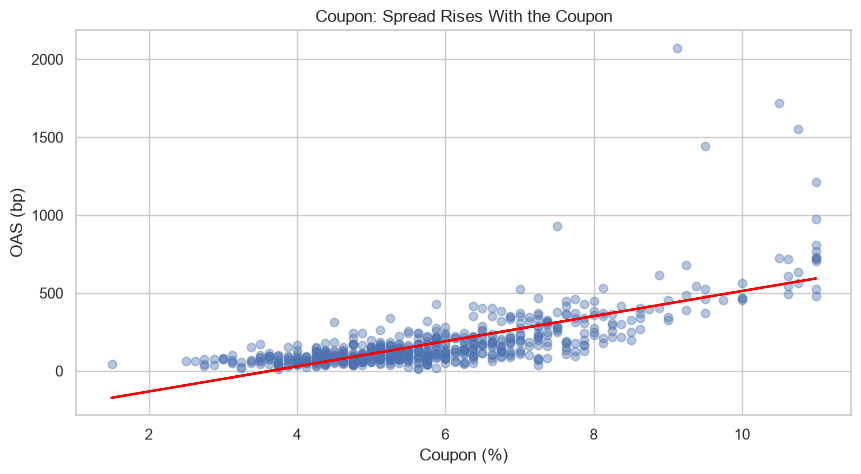

In [30]:
# the training bonds, with the fitted line across them
plt.scatter(X_train["coupon"], y_train, alpha=0.4)
plt.plot(X_train["coupon"], model_coupon.predict(X_train[features_coupon]), color="red")
plt.xlabel("Coupon (%)")
plt.ylabel("OAS (bp)")
plt.title("Coupon: Spread Rises With the Coupon")
plt.show()

### Interpretation

Each extra 1 percent of coupon goes with about 81 bp more fitted spread.

Below a coupon of about 3.6 percent the line goes negative, like the rating line.

Coupon accounts for about 50 percent of the variation, close to rating.

A coupon is set from the bond's yield, and the yield holds the spread, so coupon carries part of the answer.

**That leaves two strong candidates and one weak one, all judged so far on bonds they were fitted on. Now we score them on bonds they have never seen.**

# Model Performance Evaluation

One function scores any model on any set of bonds with five measures:

* **MAE** (bp): the average length of a gray line.
* **RMSE** (bp): square each miss, average, take the root, so long misses count far more.
* **MAPE** (%): each miss as a percent of the bond's own spread, averaged.
* **R-squared**: the share of the variation in spread the model accounts for.
* **Adj. R-squared**: R-squared with a small charge for each feature. With one feature it sits almost on top of R-squared; it starts to matter on Day 2, when features are added.

## The Scoring Function

In [31]:
# MAPE: each miss as a percent of the actual spread, averaged
def mape_score(actual, fitted):
    return np.mean(np.abs(actual - fitted) / actual) * 100


# adjusted R-squared: R-squared with a charge for each feature
def adj_r2_score(predictors, actual, fitted):
    r2 = r2_score(actual, fitted)
    n = predictors.shape[0]  # number of bonds
    k = predictors.shape[1]  # number of features
    return 1 - (1 - r2) * (n - 1) / (n - k - 1)


# the five measures for one model on one set of bonds, as a one-row table
def model_performance_regression(model, predictors, target):
    fitted = model.predict(predictors)
    return pd.DataFrame({
        "RMSE": [np.sqrt(mean_squared_error(target, fitted))],
        "MAE": [mean_absolute_error(target, fitted)],
        "MAPE": [mape_score(target, fitted)],
        "R-squared": [r2_score(target, fitted)],
        "Adj. R-squared": [adj_r2_score(predictors, target, fitted)],
    })

## Scoring OAS vs Rating Score

In [32]:
# how the rating line does on the bonds it was fitted on
score_train_perf = model_performance_regression(model_score, X_train[features_score], y_train)
score_train_perf

,RMSE,MAE,MAPE,R-squared,Adj. R-squared
0,133.046,65.624,56.365,0.523,0.522


On the training bonds the rating line misses by 65.6 bp on average, with an RMSE of 133.0 bp.

**Predict 2**

Write down the rating line's MAE on the 206 test bonds, in bp.

In [33]:
# how the rating line does on bonds it has never seen
score_test_perf = model_performance_regression(model_score, X_test[features_score], y_test)
score_test_perf

,RMSE,MAE,MAPE,R-squared,Adj. R-squared
0,108.331,57.662,42.370,0.553,0.551


On the test bonds: MAE 57.7 bp, RMSE 108.3 bp, R-squared 0.55.

A line with two numbers has almost nothing to memorise, so its training and test errors land close together; which side comes out lower is the luck of which bonds fell where.

MAPE (42.4 percent) is driven by the tightest bonds, where the line goes below zero.

A AAA bond at 23 bp fitted at -140.0 bp is a 709 percent miss; the widest miss, 1,120 bp on a CCC+ bond, is only 70 percent.

So a desk reads the miss in bp, with MAE.

## Scoring OAS vs Duration

**Predict 3**

Write down the duration line's R-squared on the test bonds.

In [34]:
# the duration line on training bonds, then on test bonds
duration_train_perf = model_performance_regression(model_duration, X_train[features_duration], y_train)
duration_test_perf = model_performance_regression(model_duration, X_test[features_duration], y_test)
duration_test_perf

,RMSE,MAE,MAPE,R-squared,Adj. R-squared
0,162.277,97.789,83.459,-0.003,-0.008


Test R-squared is -0.003, below zero.

On test bonds, R-squared compares the line with a flat line at those bonds' own average spread.

Below zero means the line misses by more than that flat line.

## Scoring OAS vs Coupon

In [35]:
# the coupon line on training bonds, then on test bonds
coupon_train_perf = model_performance_regression(model_coupon, X_train[features_coupon], y_train)
coupon_test_perf = model_performance_regression(model_coupon, X_test[features_coupon], y_test)
coupon_test_perf

,RMSE,MAE,MAPE,R-squared,Adj. R-squared
0,107.918,63.972,51.255,0.556,0.554


Test MAE 64.0 bp and R-squared 0.556: close to the rating line.

**Each model has a score on unseen bonds. Next, line them up side by side.**

# Model Performance Comparison

## Training Performance

In [36]:
# training performance: one column per model
models_train_comp = pd.concat([score_train_perf.T, duration_train_perf.T, coupon_train_perf.T], axis=1)
models_train_comp.columns = ["OAS vs Rating Score", "OAS vs Duration", "OAS vs Coupon"]
models_train_comp

,OAS vs Rating Score,OAS vs Duration,OAS vs Coupon
RMSE,133.046,192.127,135.597
MAE,65.624,115.442,77.223
MAPE,56.365,103.479,66.227
R-squared,0.523,0.005,0.504
Adj. R-squared,0.522,0.003,0.503


## Test Performance

In [37]:
# test performance: one column per model
models_test_comp = pd.concat([score_test_perf.T, duration_test_perf.T, coupon_test_perf.T], axis=1)
models_test_comp.columns = ["OAS vs Rating Score", "OAS vs Duration", "OAS vs Coupon"]
models_test_comp

,OAS vs Rating Score,OAS vs Duration,OAS vs Coupon
RMSE,108.331,162.277,107.918
MAE,57.662,97.789,63.972
MAPE,42.370,83.459,51.255
R-squared,0.553,-0.003,0.556
Adj. R-squared,0.551,-0.008,0.554


On the test bonds, rating score has the smallest typical miss: 57.7 bp, against 64.0 for coupon and 97.8 for duration.

Coupon edges rating on test RMSE and R-squared by a hair (107.9 against 108.3 bp): the measures can disagree, so say which one you read.

The rating line's training and test errors are close (MAE 65.6 against 57.7 bp), so it is not overfitting.

Choosing a model by its test score spends some of the test set's honesty; later days keep a separate validation set for choosing.

**Rating score gives the smallest typical miss on unseen bonds. Next: what a model that fails this test looks like.**

# What Overfitting Looks Like

## The Memoriser

The memoriser writes down every training bond's spread.

Asked about a bond it has seen, it reads its notes.

Asked about a new bond, it answers with the training average.

In [38]:
# the memoriser's notes: every training bond's spread, by CUSIP
notes = dict(zip(data.loc[X_train.index, "cusip"], y_train))

# its answers: from the notes where it can, the training average where it cannot
memo_train = data.loc[X_train.index, "cusip"].map(notes).fillna(y_train.mean())
memo_test = data.loc[X_test.index, "cusip"].map(notes).fillna(y_train.mean())

# the memoriser's MAE on the bonds it has seen, in bp
memo_train_mae = mean_absolute_error(y_train, memo_train)
print("Training MAE:", round(memo_train_mae, 1), "bp")

Training MAE: 0.0 bp


**Predict 4**

The memoriser misses the bonds it has seen by 0.0 bp.

Write down its MAE on the test bonds.

In [39]:
# the memoriser's MAE on bonds it has never seen, in bp
memo_test_mae = mean_absolute_error(y_test, memo_test)
print("Test MAE:", round(memo_test_mae, 1), "bp")

Test MAE: 97.4 bp


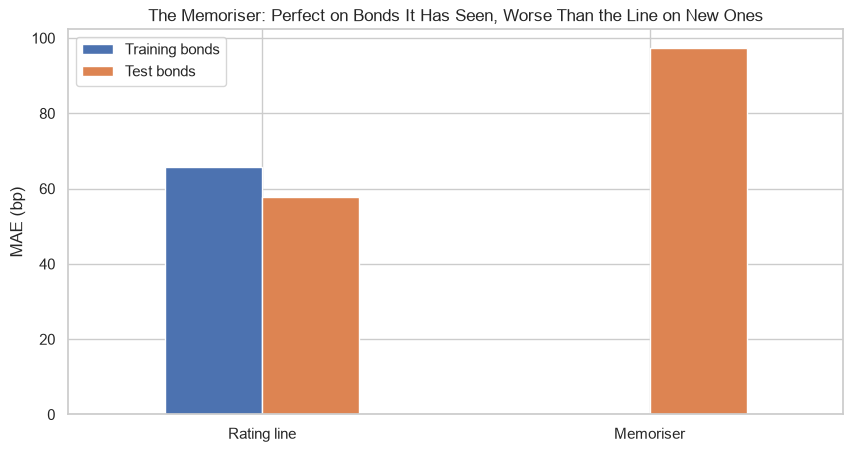

In [40]:
# MAE in bp on seen and unseen bonds, for the rating line and the memoriser
errors = pd.DataFrame({"Training bonds": [score_train_perf["MAE"][0], memo_train_mae],
                       "Test bonds": [score_test_perf["MAE"][0], memo_test_mae]},
                      index=["Rating line", "Memoriser"])
errors.plot.bar(rot=0)
plt.ylabel("MAE (bp)")
plt.title("The Memoriser: Perfect on Bonds It Has Seen, Worse Than the Line on New Ones")
plt.show()

0.0 bp on bonds it has seen, 97.4 bp on bonds it has not: worse than the rating line.

A big gap between training and test errors is overfitting.

The rating line has none, and the memoriser has all of it.

**A perfect training score proves nothing. A model is only as good as its score on bonds it has never seen.**

# Residual Analysis

## Residuals vs Fitted Values

Q. Are the misses random, or do they follow a pattern?

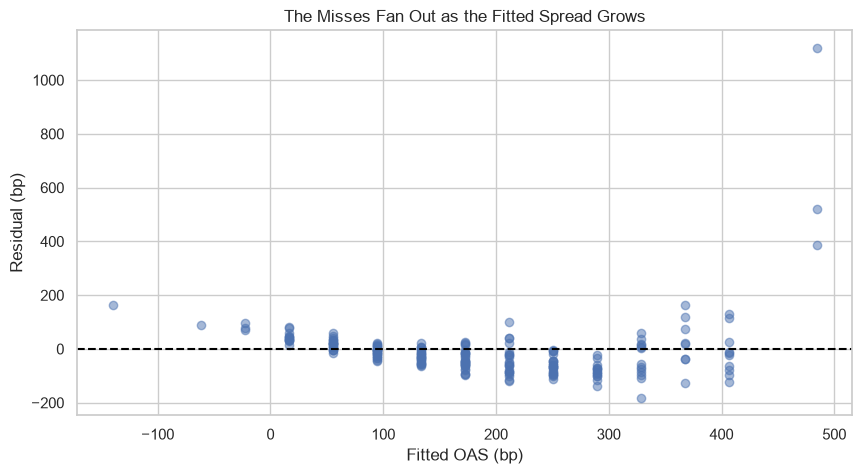

In [41]:
# each test bond's fitted spread, and its miss: actual spread minus fitted spread
fitted_test = model_score.predict(X_test[features_score])
residuals_test = y_test - fitted_test

# misses against the fitted spread, with zero marked
plt.scatter(fitted_test, residuals_test, alpha=0.5)
plt.axhline(0, color="black", linestyle="--")
plt.xlabel("Fitted OAS (bp)")
plt.ylabel("Residual (bp)")
plt.title("The Misses Fan Out as the Fitted Spread Grows")
plt.show()

The misses make a U: above zero at both ends, below zero in the middle.

That is the curve from the OAS by Rating chart again: a straight line is too low at both ends and too high in the middle.

The misses also fan out as the fitted spread grows: high yield bonds are missed by much more than investment grade bonds.

One dot sits far above the rest.

## The Largest Misses

Q. Which bond is the dot far above the rest?

In [42]:
# the test bonds with the largest misses, in bp
test_bonds = data.loc[X_test.index, ["cusip", "issuer", "rating", "oas"]]
test_bonds["fitted"] = fitted_test
test_bonds["residual"] = residuals_test
test_bonds.sort_values("residual", ascending=False).head().round(1)

,cusip,issuer,rating,oas,fitted,residual
196,99038MAC3,Praxiskan Finance,CCC+,1605,484.800,"1,120.200"
199,99038MAF6,Praxiskan Finance,CCC+,1004,484.800,519.200
198,99038MAE9,Praxiskan Finance,CCC+,871,484.800,386.200
393,99074WAB8,Wyxundra Energy,B+,532,367.700,164.300
155,99030EAD7,Dralane Networks,AAA,23,-140.000,163.000


The largest miss is Praxiskan Finance `99038MAC3`, CCC+: actual OAS 1,605 bp, fitted 484.8 bp, a residual of 1,120.2 bp.

That one bond carries about half (52 percent) of the line's total squared test miss, much of why RMSE is close to twice MAE (108.3 against 57.7 bp).

A residual is the model's miss on one bond, not a view on the bond: the line knows only the rating.

**The misses grow with the spread, and the line has the wrong shape at both ends: Day 2 gives every rating its own step, and Day 4 bends the line with log spreads.**

# Insights and Conclusion

Rating score gives the smallest typical miss of the three lines: about 39 bp per notch, and 57.7 bp on unseen bonds.

Coupon comes close because it carries part of the spread itself; duration alone says almost nothing.

The rating line is a straight line on a curve: below zero at AAA, short of the widest high yield bonds.

Its training and test errors are close, so it is not overfitting.

203 of the 206 test bonds share an issuer with a training bond, so "never seen" is weaker than it sounds; Day 5 splits by issuer.

**One straight line on rating carries about half the story; Day 2 gives every rating its own step.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Frame a modeling task and run a data overview.
* Read univariate and bivariate charts, and spot a feature built from the target.
* Fit a simple linear regression, write its equation, and say what its slope and R-squared mean.
* Score and compare models on training and test bonds with five measures.
* Read a residual plot, and tell a model that has learned from one that has memorised.

## Exercises

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [43]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**Investment Grade Only**

Q. Fit OAS vs Rating Score on the investment grade bonds only. Split them with `test_size=0.25` and `random_state=SEED`, fit on their training bonds, and store the slope in bp per notch in `ex1_slope` and the test MAE in bp in `ex1_test_mae_bp`.

In [44]:
# only the investment grade bonds
ig = data[data["grade"] == "Investment Grade"]

# the same split and the same model
Xi_train, Xi_test, yi_train, yi_test = train_test_split(ig[["score"]], ig["oas"], test_size=0.25, random_state=SEED)
model_ig = LinearRegression()
model_ig.fit(Xi_train, yi_train)

ex1_slope = model_ig.coef_[0]
ex1_test_mae_bp = mean_absolute_error(yi_test, model_ig.predict(Xi_test))
print(ex1_slope, ex1_test_mae_bp)

16.65602647244852 21.826984274920797


16.7 bp per notch, less than half the all-bond slope, and a test MAE of 21.8 bp.

Inside investment grade the spread steps are small, so the line is flatter and its misses are smaller in bp.

The two MAEs describe different sets of bonds, so neither line is the better one.

In [45]:
check("Exercise 1 the slope", ex1_slope, 16.65602647244852)
check("Exercise 1 the test MAE", ex1_test_mae_bp, 21.826984274920797)

Exercise 1 the slope: correct
Exercise 1 the test MAE: correct


### Exercise 2

**The Miss by Grade**

Q. Using the rating line fitted on all training bonds, compute its test MAE in bp separately for investment grade and high yield test bonds. Store a dictionary of grade to MAE, rounded to 1 decimal, in `ex2_mae_by_grade`.

In [46]:
# each test bond's miss in bp, with its grade beside it
misses = pd.DataFrame({"grade": data.loc[X_test.index, "grade"], "miss": residuals_test.abs()})

# the average miss within each grade
ex2_mae_by_grade = misses.groupby("grade")["miss"].mean().round(1).to_dict()
print(ex2_mae_by_grade)

{'High Yield': 94.2, 'Investment Grade': 38.9}


38.9 bp for investment grade and 94.2 bp for high yield.

One overall MAE of 57.7 bp hides a miss more than twice as large on one side of the scale.

In [47]:
check("Exercise 2 the MAE by grade", ex2_mae_by_grade, {'High Yield': 94.2, 'Investment Grade': 38.9})

Exercise 2 the MAE by grade: correct


### Exercise 3

**A Feature That Already Knows the Answer**

Q. Fit a simple regression of OAS on `yield_pct` using the same training and test bonds, and store its test R-squared in `ex3_test_r2`. Then write one sentence on why this model must not be used.

In [48]:
# the yield of the same training and test bonds
yield_train = data.loc[X_train.index, ["yield_pct"]]
yield_test = data.loc[X_test.index, ["yield_pct"]]

# fit OAS on yield, then score it on the test bonds
model_yield = LinearRegression()
model_yield.fit(yield_train, y_train)
ex3_test_r2 = r2_score(y_test, model_yield.predict(yield_test))
print(ex3_test_r2)

0.9766980462894198


Test R-squared is 0.98: almost perfect.

The yield is a Treasury yield plus the OAS, so the feature contains the target, and the model is reading the answer off its input.

When a score looks too good, check whether a feature was built from the target.

The same goes for `dts`.

In [49]:
check("Exercise 3 the test R-squared", ex3_test_r2, 0.9766980462894198)

Exercise 3 the test R-squared: correct


### Exercise 4: AI check

**The Function That Peeked**

You asked an AI assistant for a function that fits OAS vs Rating Score on the training bonds and returns its test MAE.

This came back.

It runs, and the number looks about right.

Test it against a number you already trust, then find the one bug.

In [50]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def rating_line_test_mae(bonds):
    # split the bonds, fit the line on the training bonds, score it on the test bonds
    train, test = train_test_split(bonds, test_size=0.25, random_state=SEED)
    model = LinearRegression()
    model.fit(bonds[["score"]], bonds["oas"])
    return mean_absolute_error(test["oas"], model.predict(test[["score"]]))

# the check against a number we trust: the test MAE from the performance table
print(round(rating_line_test_mae(data), 1))

56.9


Q. The performance table gave a test MAE of 57.7 bp for this model and split. Does `rating_line_test_mae(data)` agree? If not, fix the one wrong line and store the fixed function's result in `ex4_test_mae_bp`.

In [51]:
# the fix: fit the line on the training bonds only
def rating_line_test_mae(bonds):
    # split the bonds, fit the line on the training bonds, score it on the test bonds
    train, test = train_test_split(bonds, test_size=0.25, random_state=SEED)
    model = LinearRegression()
    model.fit(train[["score"]], train["oas"])
    return mean_absolute_error(test["oas"], model.predict(test[["score"]]))

ex4_test_mae_bp = rating_line_test_mae(data)
print(round(ex4_test_mae_bp, 1))

57.7


The check printed 56.9, not 57.7.

The fit line uses `bonds`, all 821 of them, so the 206 test bonds are fitted on and then scored as if unseen.

The fix is `model.fit(train[["score"]], train["oas"])`, which returns 57.7.

The leaky number is slightly better than the honest one.

Leakage does not raise an error.

It looks like a good model.

The comment promised training bonds only, and one word in the code broke that promise.

Test a function against a number you already trust before you trust its numbers.

In [52]:
check("Exercise 4 the fixed function's test MAE", ex4_test_mae_bp, 57.66200909910362)

Exercise 4 the fixed function's test MAE: correct


## Congratulations!

You built and judged your first three machine learning models today, start to finish.
You framed the problem, checked the data, fitted three lines, and scored each on 206 bonds it had never seen.
You found that rating carries about half the story, duration on its own almost none of it, and one CCC+ bond half of the rating line's squared miss on the test bonds.
You caught a perfect model that had only memorised, and a function that peeked at its test bonds.
In Day 2 every rating gets its own step and duration joins the rating, and you see what that does to the miss.